# Proporción de puntos seleccionados por la historia del residuo

10 semillas pareadas, 100 pasos de calentamiento y 2000 de continuación. Se mantiene un lote de 128 puntos y actualización cada 100 pasos. Sobol puro representa cero puntos elegidos por los modos.

QR básico está limitado por el rango retenido: aumentar su límite no garantiza más puntos. Aquí se conservan esas variantes y se añaden 32, 64 y 128 puntos mediante QR inicial seguido por selección voraz de ganancia log-det en los mismos modos. Esto es una extensión de la selección anterior, no una reproducción adicional del artículo QR-DEIM.

## Resultados al mismo presupuesto

| Variante | Puntos de modos reales (mín–máx) | RMSE (media ± DE) | Residuo RMS | Primer cruce | Bajo umbral al final | Últimos checkpoints bajo umbral |
|---|---:|---:|---:|---:|---:|---:|
| Sobol (0 puntos de modos) | 0–0 | 0.1800 ± 0.0359 | 0.3664 | 10/10 | 10/10 | 10/10 |
| POD + QR por rango | 2–14 | 0.2198 ± 0.0359 | 0.1457 | 10/10 | 10/10 | 10/10 |
| POD: 32 puntos | 32–32 | 0.2124 ± 0.0554 | 0.1236 | 10/10 | 10/10 | 10/10 |
| POD: 64 puntos | 64–64 | 0.2516 ± 0.0566 | 0.1287 | 10/10 | 10/10 | 10/10 |
| POD: 128 puntos | 128–128 | 0.3049 ± 0.0188 | 0.1452 | 10/10 | 10/10 | 10/10 |
| PCA + media + QR por rango | 4–16 | 0.2051 ± 0.0451 | 0.1445 | 10/10 | 10/10 | 10/10 |
| PCA + media: 32 puntos | 32–32 | 0.2167 ± 0.0455 | 0.1256 | 10/10 | 10/10 | 10/10 |
| PCA + media: 64 puntos | 64–64 | 0.2298 ± 0.0572 | 0.1241 | 10/10 | 10/10 | 10/10 |
| PCA + media: 128 puntos | 128–128 | 0.2908 ± 0.0193 | 0.1447 | 10/10 | 10/10 | 10/10 |

El umbral es RMSE de validación ≤ 0.35; se distingue el primer cruce, el estado final y permanecer bajo él en los últimos 5 checkpoints. Si no hay suficientes observaciones, no se acredita estabilidad. Las semillas sin cruce son censuradas. El test no decide el umbral ni la selección.

## Comparación visual

**Fracción de puntos**

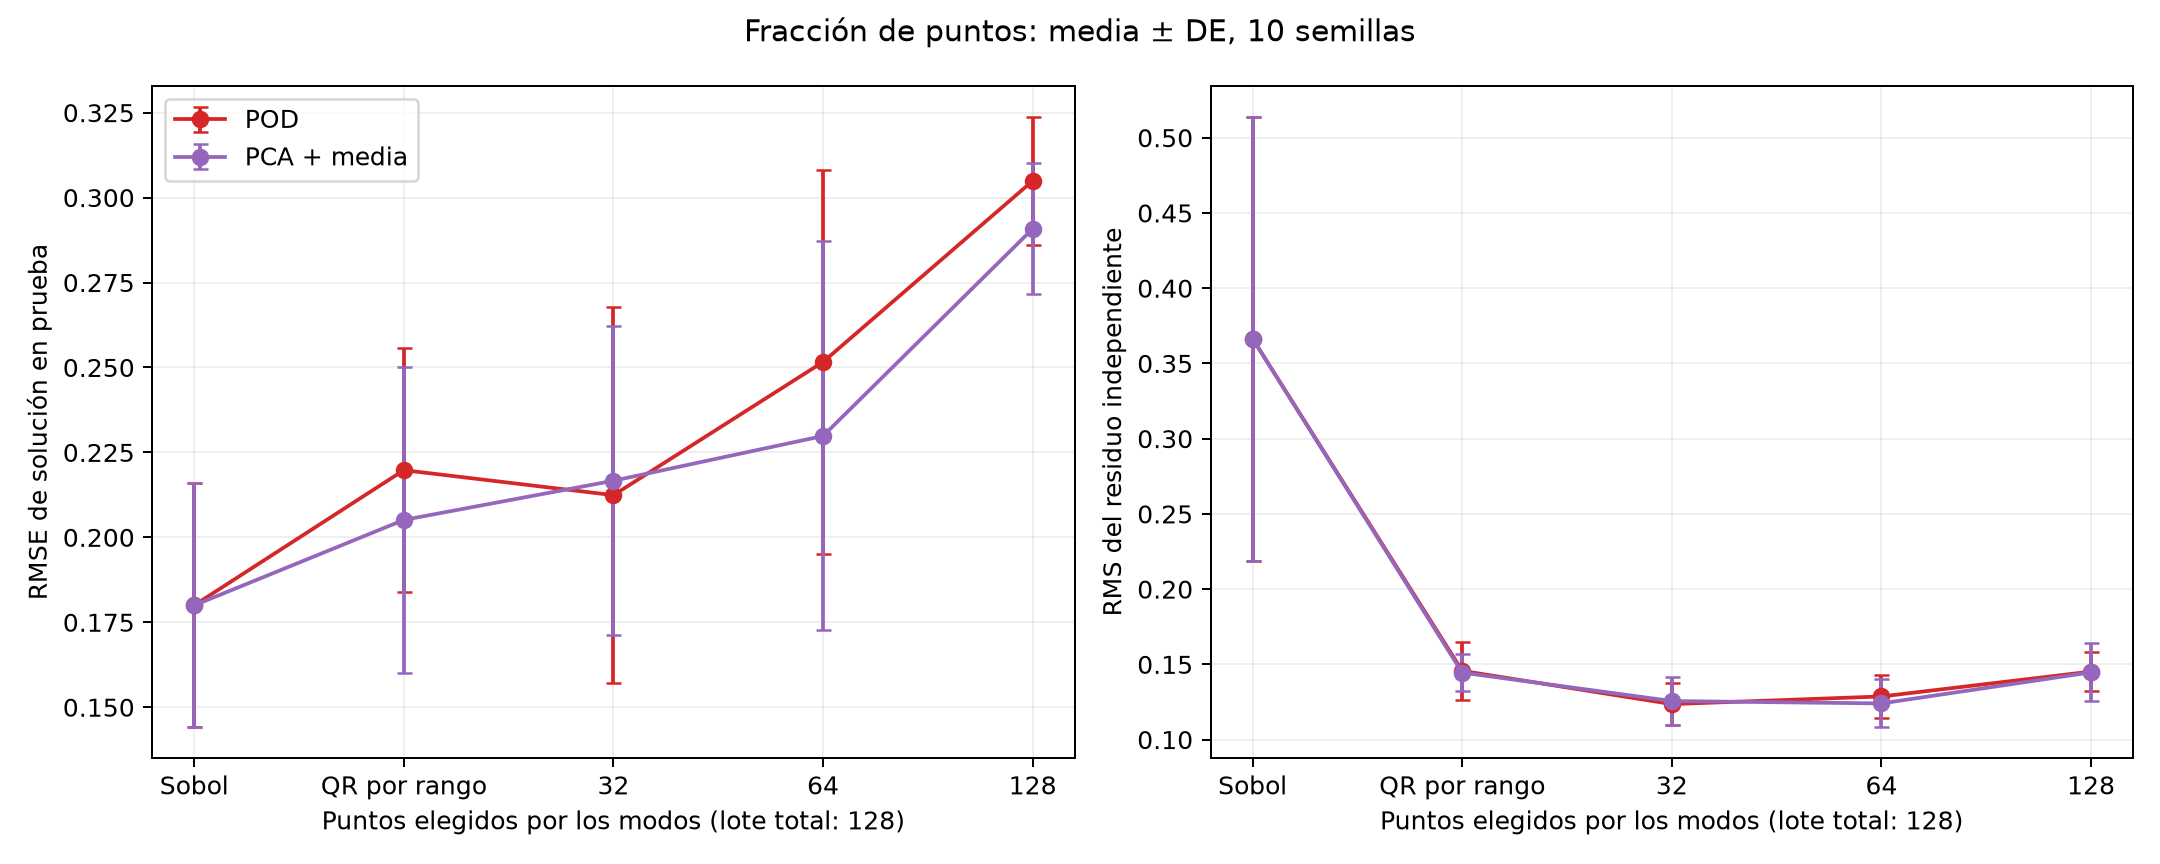

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_selection/qr_fraction_ablation_10_seeds_2k_v1/fraction_ablation.png'), format='png', embed=True))


## Evolución de validación

**Validación**

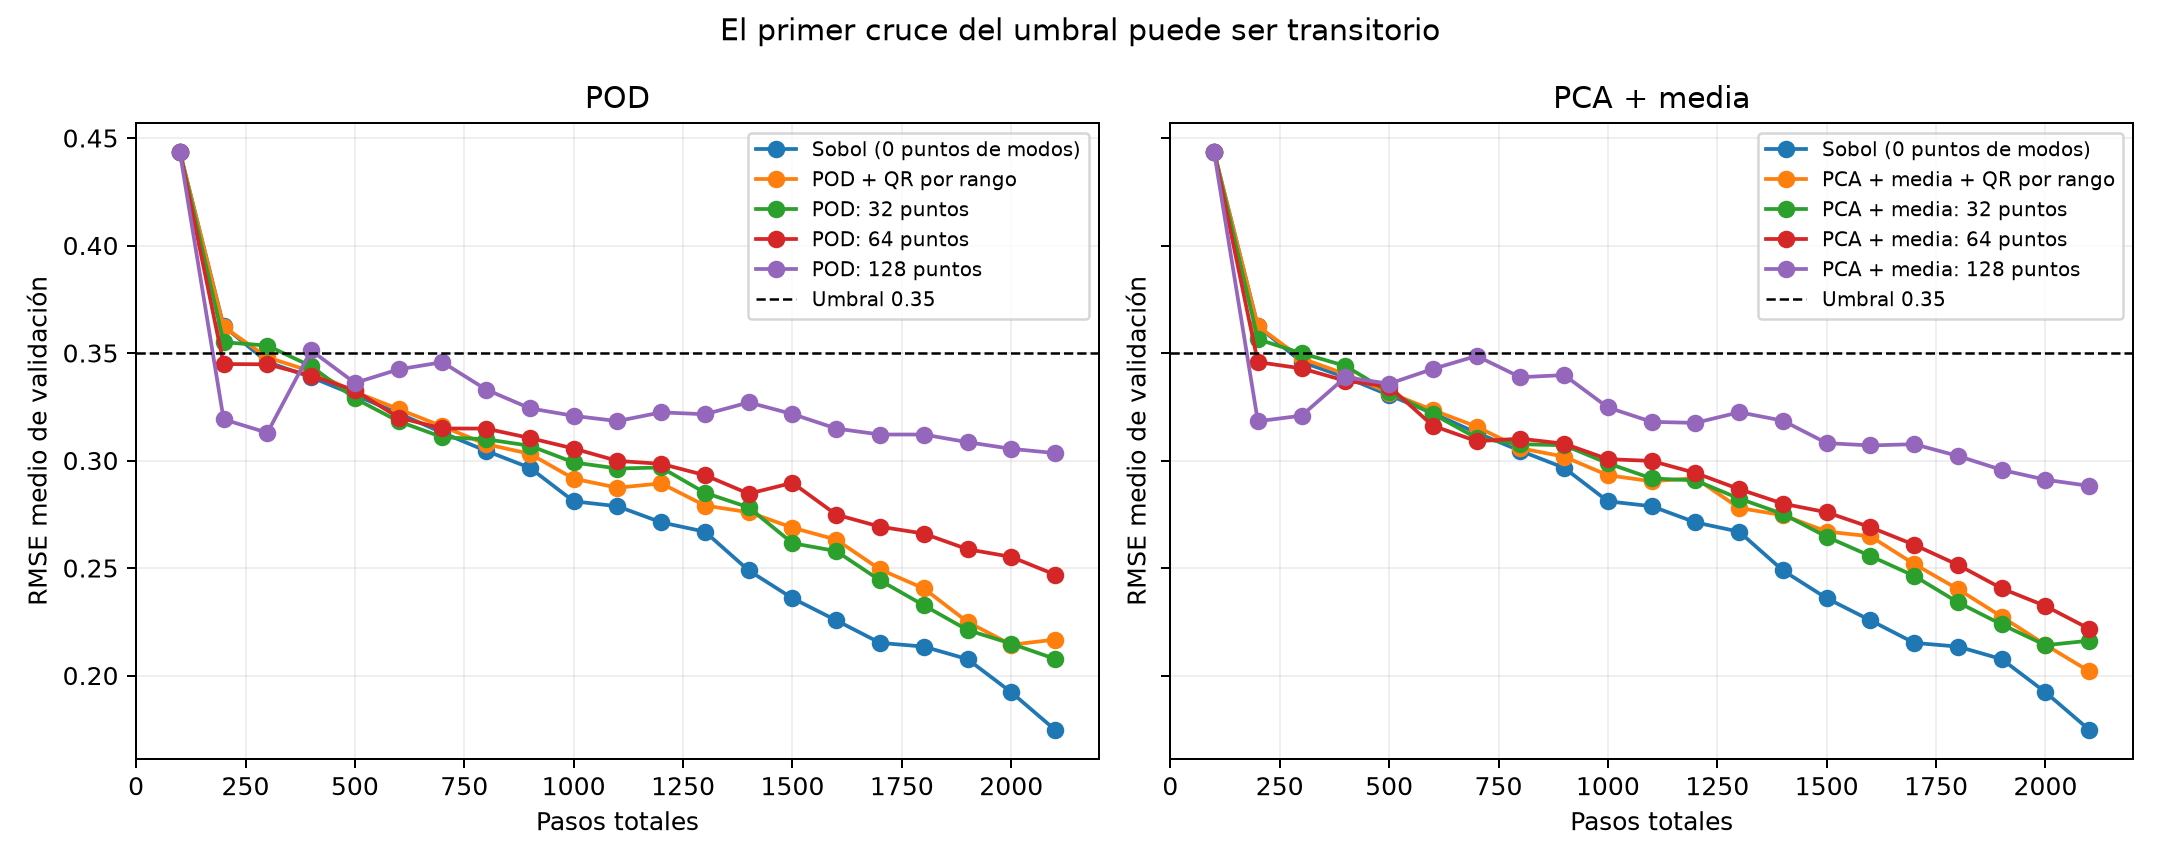

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_selection/qr_fraction_ablation_10_seeds_2k_v1/fraction_validation.png'), format='png', embed=True))


Un primer cruce cuenta incluso si el entrenamiento posterior empeora. La tabla distingue ese evento de terminar bajo el umbral.

## Interpretación y límites

El número de puntos seleccionados se registra en cada actualización; las 32/64/128 filas elegidas son índices distintos del conjunto candidato. El número de modos sigue fijado por energía de 0.99 y máximo 20. El complemento usa el mismo prefijo Sobol por semilla y actualización, también compartido entre POD y PCA.

Las diferencias pareadas se guardan frente a Sobol y frente al QR limitado por rango de cada enfoque. Un menor residuo independiente debe acompañarse de mejora en la solución y las condiciones iniciales y de frontera. El presupuesto corto limita las conclusiones. Los tiempos incluyen evaluaciones y compilación inicial; no se usan para afirmar aceleración.

## Cambio al ampliar el entrenamiento

Comparación pareada de 300 a 2000 pasos de continuación, con las mismas semillas, lotes y protocolo. Máxima diferencia en la validación de los checkpoints compartidos: 0.

| Variante | Δ RMSE prueba (largo − corto) | Semillas que mejoran |
|---|---:|---:|
| sobol | -0.1597 ± 0.0309 | 10/10 |
| pod_qr_rank | -0.1230 ± 0.0319 | 10/10 |
| pod_qr_32 | -0.1332 ± 0.0446 | 10/10 |
| pod_qr_64 | -0.0902 ± 0.0527 | 10/10 |
| pod_qr_128 | -0.0456 ± 0.0263 | 10/10 |
| pca_mean_qr_rank | -0.1363 ± 0.0387 | 10/10 |
| pca_mean_qr_32 | -0.1284 ± 0.0383 | 10/10 |
| pca_mean_qr_64 | -0.1091 ± 0.0548 | 10/10 |
| pca_mean_qr_128 | -0.0506 ± 0.0258 | 10/10 |


## Lectura del resultado

Sobol obtiene RMSE medio de solución 0.1800; la variante guiada con menor media es PCA + media + QR por rango (0.2051). El menor residuo independiente entre las variantes guiadas corresponde a POD: 32 puntos (0.1236), frente a 0.3664 con Sobol. Las condiciones iniciales y de frontera se conservan en los CSV para analizar este compromiso entre ajuste de la solución y residuo.

90 de 90 combinaciones permanecen bajo el umbral 0.35 en los últimos 5 controles. Alcanzar ese umbral no implica igual precisión final. Este experimento no selecciona un umbral nuevo después de observar las pruebas ni demuestra aceleración general.

In [ ]:
import json
from pathlib import Path
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
output = root / 'pca_collocation/results/burgers/collocation_selection/qr_fraction_ablation_10_seeds_2k_v1'
summary = json.loads((output / 'summary.json').read_text(encoding='utf-8'))
summary['methods']